# 01 · The Popularity Baseline

> **The one rule of this project: report the popularity baseline *first*, always.**

Recommending the most-rated items to *everyone* — ignoring the individual user
entirely — is a shockingly strong baseline. Popular items are popular for a
reason, and most ranking metrics reward getting the obvious hits right. A
recommender that has not been compared to popularity has not been evaluated.

This notebook loads MovieLens-small, sets up an honest evaluation (hold out each
user's most recent interactions, recommend a top-k list, score it with *ranking*
metrics — not accuracy), and records the popularity baseline. **That number is the
bar every real method in this project must clear — and clearing it is harder than
it looks.**

Every figure is saved to `outputs/figures/*.png` and every result to
`outputs/data/*.json`.

In [1]:
# --- make the notebook runnable from anywhere: find the repo root, add to path, chdir ---
import os
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)

%matplotlib inline
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

from src.artifacts import save_figure, save_json
from src.config import get_settings

SETTINGS = get_settings()
print("project root:", _root)
print("seed:", SETTINGS.seed, "| top_k:", SETTINGS.top_k)

project root: /workspaces/recommender_101
seed: 42 | top_k: 10


## Load the ratings and build the sparse user–item matrix

We prefer the cached/frozen copy under `data/`. If it is missing (e.g. no network
and no cache), we fall back to a synthetic dataset so the notebook always runs.

In [2]:
from src.data.ratings import item_popularity, load_movielens, make_synthetic_ratings

try:
    data = load_movielens()
    titles = data.item_titles or [str(i) for i in data.item_ids]
    source = "MovieLens-small"
except Exception as exc:  # pragma: no cover - only if download + cache both unavailable
    print("Falling back to synthetic data:", exc)
    syn = make_synthetic_ratings(seed=SETTINGS.seed)
    data = type("D", (), {"matrix": syn.observed, "timestamps": None, "item_features": syn.item_features})
    titles = [f"item {i}" for i in range(syn.observed.shape[1])]
    source = "synthetic"

matrix = data.matrix
n_users, n_items = matrix.shape
n_ratings = matrix.nnz
density = n_ratings / (n_users * n_items)

stats = {
    "source": source,
    "n_users": int(n_users),
    "n_items": int(n_items),
    "n_ratings": int(n_ratings),
    "density": float(density),
    "sparsity": float(1 - density),
    "mean_ratings_per_user": float(n_ratings / n_users),
    "rating_min": float(matrix.data.min()),
    "rating_max": float(matrix.data.max()),
    "mean_rating": float(matrix.data.mean()),
}
print(f"{source}: {n_users} users x {n_items} items, {n_ratings} ratings")
print(f"density {density:.4%}  (the table is {1 - density:.2%} empty)")
save_json(stats, "01_dataset_stats")
stats

MovieLens-small: 610 users x 9724 items, 100836 ratings
density 1.7000%  (the table is 98.30% empty)


{'source': 'MovieLens-small',
 'n_users': 610,
 'n_items': 9724,
 'n_ratings': 100836,
 'density': 0.016999683055613623,
 'sparsity': 0.9830003169443864,
 'mean_ratings_per_user': 165.30491803278687,
 'rating_min': 0.5,
 'rating_max': 5.0,
 'mean_rating': 3.501556983616962}

## What the data looks like

Two facts set up everything that follows: ratings are **skewed high** (people rate
things they chose to watch), and item popularity is a **long tail** — a handful of
blockbusters soak up most of the ratings, which is exactly why "recommend the head
of the tail to everyone" is so hard to beat.

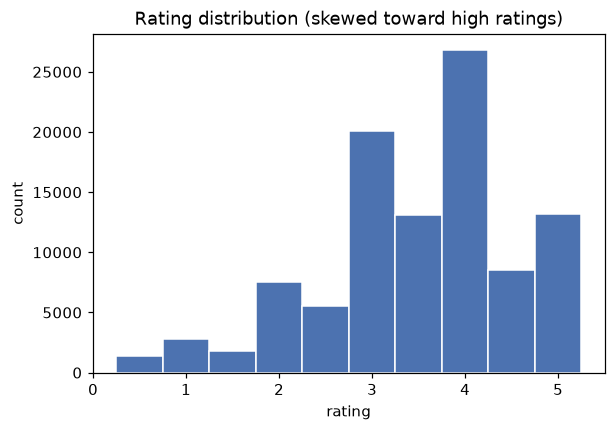

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(matrix.data, bins=np.arange(0.25, 5.75, 0.5), color="#4C72B0", edgecolor="white")
ax.set_xlabel("rating")
ax.set_ylabel("count")
ax.set_title("Rating distribution (skewed toward high ratings)")
save_figure(fig, "01_rating_distribution")
plt.show()

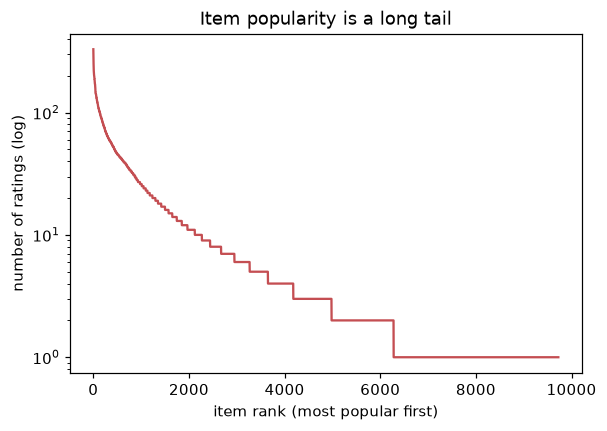

,rank,title,n_ratings
0,1,Forrest Gump (1994),329
1,2,"Shawshank Redemption, The (1994)",317
2,3,Pulp Fiction (1994),307
3,4,"Silence of the Lambs, The (1991)",279
4,5,"Matrix, The (1999)",278
5,6,Star Wars: Episode IV - A New Hope (1977),251
6,7,Jurassic Park (1993),238
7,8,Braveheart (1995),237
8,9,Terminator 2: Judgment Day (1991),224
9,10,Schindler's List (1993),220


In [4]:
popularity = item_popularity(matrix)
order = np.argsort(popularity)[::-1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, n_items + 1), popularity[order], color="#C44E52")
ax.set_yscale("log")
ax.set_xlabel("item rank (most popular first)")
ax.set_ylabel("number of ratings (log)")
ax.set_title("Item popularity is a long tail")
save_figure(fig, "01_popularity_long_tail")
plt.show()

top_popular = [
    {"rank": int(r + 1), "title": titles[order[r]], "n_ratings": int(popularity[order[r]])}
    for r in range(10)
]
save_json(top_popular, "01_top_popular_items")
pd.DataFrame(top_popular)

## Honest evaluation: hold out each user's most recent interactions

For every user we hold out their `n_holdout` most recent ratings (by timestamp)
as a test set and train on the rest. The task: rank the full catalog and see
whether the held-out items land near the top. We score with **ranking** metrics —
precision@k, recall@k, NDCG@k, MAP — plus **catalog coverage**. (Accuracy / RMSE
is the wrong tool here; that is the lesson of the metrics project.)

In [5]:
from src.evaluation.ranking import catalog_coverage, evaluate_ranking
from src.evaluation.splits import leave_last_out
from src.recommenders.popularity import PopularityRecommender

split = leave_last_out(
    matrix,
    n_holdout=SETTINGS.split.n_holdout,
    min_train=SETTINGS.split.min_train,
    timestamps=getattr(data, "timestamps", None),
    seed=SETTINGS.seed,
)
k = SETTINGS.top_k
print(f"holding out {SETTINGS.split.n_holdout} items/user -> {split.n_evaluated} users evaluated")

pop = PopularityRecommender().fit(split.train)
recs = pop.recommend_all(k=k)
evaluated_users = np.array(sorted(split.test_items))

metrics = evaluate_ranking(recs, split.test_items, k)
metrics["coverage"] = catalog_coverage(recs[evaluated_users], n_items)
metrics = {"k": k, "n_evaluated": split.n_evaluated, **metrics}
save_json(metrics, "01_popularity_metrics")
pd.Series(metrics).to_frame("popularity")

holding out 2 items/user -> 610 users evaluated


,popularity
k,10.000000
n_evaluated,610.000000
precision@k,0.007213
recall@k,0.036066
ndcg@k,0.020891
map,0.012021
coverage,0.012546


## The bar is set

Those numbers look small in absolute terms — recommending 10 items out of
thousands and catching a couple the user rated next is genuinely hard. But this is
**the yardstick**. From here on, every method — user-based CF, item-based CF,
matrix factorization, content-based — is reported *against this line*. Keep an eye
on two things the popularity baseline quietly reveals already: its **coverage** is
tiny (it recommends the same handful of blockbusters to everyone), a weakness the
accuracy numbers hide and the Arena (notebook 04) will expose.

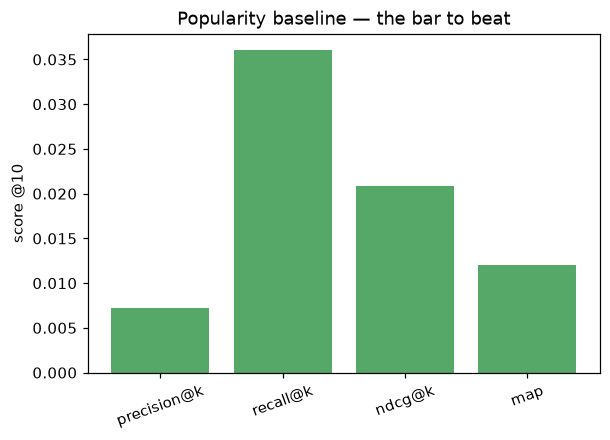

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
acc = {m: metrics[m] for m in ["precision@k", "recall@k", "ndcg@k", "map"]}
ax.bar(list(acc), list(acc.values()), color="#55A868")
ax.set_ylabel(f"score @{k}")
ax.set_title("Popularity baseline — the bar to beat")
ax.tick_params(axis="x", rotation=20)
save_figure(fig, "01_popularity_metrics_bar")
plt.show()

**Next:** [02 · Collaborative Filtering](02_collaborative_filtering.ipynb) —
"find users like you and copy them," in code, and the uncomfortable question of
whether it actually beats this baseline.